In [1]:
# Importamos las herramientas que instalamos en el Paso 1
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [4]:
# 1. Cargar el dataset MNIST directamente desde Keras
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# 2. Revisar las formas (shapes) de nuestros datos
print(f"Forma de datos de entrenamiento: {x_train.shape}") # Debería ser (60000, 28, 28)
print(f"Forma de etiquetas de entrenamiento: {y_train.shape}")
print(f"Forma de datos de prueba: {x_test.shape}")

# 3. Normalizar los píxeles
# Las imágenes tienen valores de píxeles de 0 a 255 (escala de grises).
# Las redes neuronales aprenden mucho mejor si los valores están entre 0 y 1.
x_train = x_train / 255.0
x_test = x_test / 255.0

Forma de datos de entrenamiento: (60000, 28, 28)
Forma de etiquetas de entrenamiento: (60000,)
Forma de datos de prueba: (10000, 28, 28)


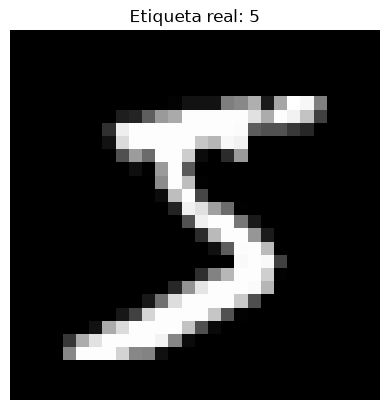

In [6]:
# 4. Validar visualmente un dato
plt.imshow(x_train[0], cmap='gray')
plt.title(f"Etiqueta real: {y_train[0]}")
plt.axis('off')
plt.show()

In [8]:
# Construimos un modelo Secuencial (capa tras capa)
model = tf.keras.models.Sequential([
    # Definimos explícitamente la forma de entrada (28x28 píxeles) para evitar el aviso de Keras
    tf.keras.Input(shape=(28, 28)),

    # Capa 1: Aplana la matriz de 28x28 píxeles a un vector de 784 números
    tf.keras.layers.Flatten(),
    
    # Capa 2 (Oculta): Capa densa con 128 neuronas. 
    # La activación 'relu' ayuda a resolver problemas no lineales (apaga valores negativos)
    tf.keras.layers.Dense(128, activation='relu'),
    
    # Capa 3 (Salida): 10 neuronas, una para cada dígito (0-9).
    # 'softmax' convierte las salidas en probabilidades que suman 1.
    tf.keras.layers.Dense(10, activation='softmax')
])

# Configuramos el proceso de aprendizaje
model.compile(optimizer='adam', # Algoritmo que ajusta los pesos eficientemente
              loss='sparse_categorical_crossentropy', # Función de error para clasificación
              metrics=['accuracy']) # Queremos medir la precisión

model.summary() # Muestra la arquitectura de la red

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Entrenamos el modelo. 
# validation_split=0.1 toma el 10% de los datos de entrenamiento para validar en cada época.
# epochs=5 significa que verá todo el dataset 5 veces.
historia = model.fit(x_train, y_train, epochs=5, validation_split=0.1)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9207 - loss: 0.2763 - val_accuracy: 0.9607 - val_loss: 0.1353
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9646 - loss: 0.1218 - val_accuracy: 0.9738 - val_loss: 0.0988
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9753 - loss: 0.0832 - val_accuracy: 0.9763 - val_loss: 0.0868
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9818 - loss: 0.0610 - val_accuracy: 0.9767 - val_loss: 0.0806
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9850 - loss: 0.0478 - val_accuracy: 0.9792 - val_loss: 0.0810


313/313 - 0s - 947us/step - accuracy: 0.9738 - loss: 0.0793

Precisión en datos de prueba (Accuracy): 97.38%


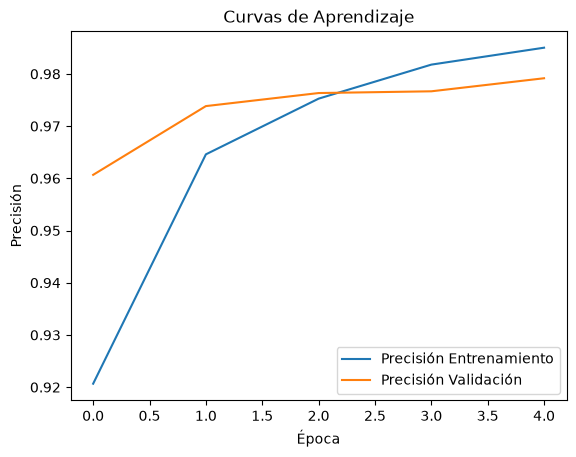

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 688us/step


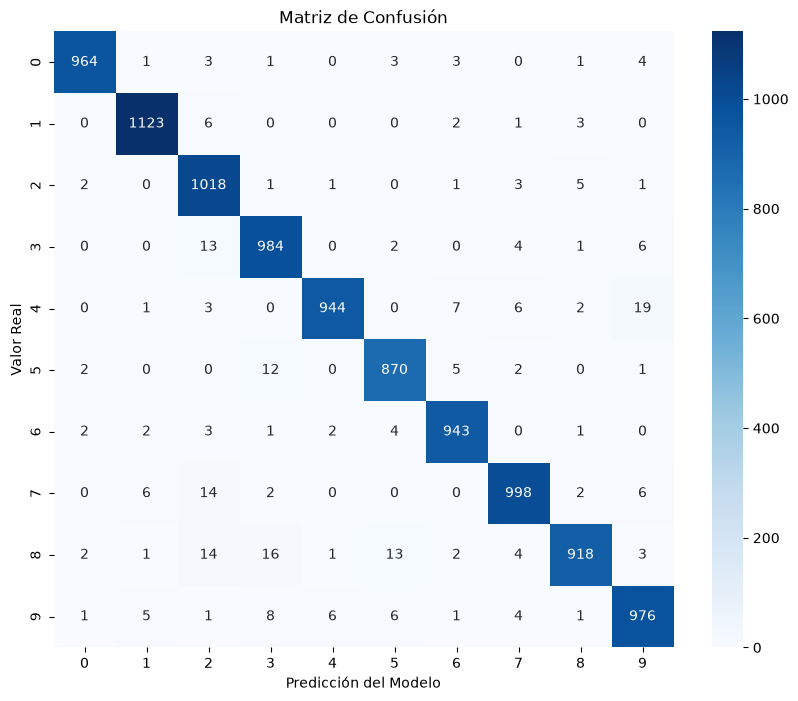

In [14]:
# 1. Evaluar con los datos de prueba (datos que el modelo nunca ha visto)
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print(f'\nPrecisión en datos de prueba (Accuracy): {test_acc*100:.2f}%')

# 2. Graficar la curva de aprendizaje (Accuracy)
plt.plot(historia.history['accuracy'], label='Precisión Entrenamiento')
plt.plot(historia.history['val_accuracy'], label='Precisión Validación')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend(loc='lower right')
plt.title('Curvas de Aprendizaje')
plt.show()

# 3. Matriz de confusión para ver en qué números se equivoca más
y_pred = np.argmax(model.predict(x_test), axis=1) # Obtenemos la predicción final
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()

In [13]:
# Guardamos el modelo entrenado en el formato moderno de Keras
model.save('Modelo.keras')
print("¡Modelo guardado exitosamente como 'Modelo.keras'!")

¡Modelo guardado exitosamente como 'Modelo.keras'!
